# Feedbacks classificados: o que aparece nos 120 exemplos?

Os textos são sintéticos e já foram processados pelo pipeline. Aqui comparo os rótulos de geração com a saída do modelo e olho a distribuição das classificações. Os números não representam a clientela de um banco.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

raiz = Path.cwd()
resultado = pd.read_csv(raiz / "data" / "feedback_enriched.csv")
df = resultado.loc[resultado["status"] == "sucesso"].copy()
print(f"Registros: {len(resultado)} | Sucessos: {len(df)} | Falhas: {len(resultado) - len(df)}")
display(df[["id", "feedback", "categoria", "assunto", "sentimento", "urgencia"]].head())

Registros: 120 | Sucessos: 120 | Falhas: 0


,id,feedback,categoria,assunto,sentimento,urgencia
0,1,"Não consigo fazer pix, aparece erro toda vez q...",pix,erro_ao_realizar_pix,negativo,alta
1,2,Queria saber onde altero meus dados pessoais n...,aplicativo,duvida_aplicativo,neutro,baixa
2,3,Meu histórico mostra dois pagamentos idênticos...,boleto,pagamento_duplicado,neutro,alta
3,4,O valor da parcela do meu empréstimo veio maio...,emprestimo,parcela_incorreta,negativo,media
4,5,Gostaria de revisar uma cobrança porque o valo...,boleto,cobranca_incorreta,neutro,media


## Conferência dos rótulos

A referência veio da criação dos exemplos, não de uma revisão humana independente. Conto os 120 IDs no denominador, inclusive se algum processamento falhar.

In [4]:
referencia = pd.read_csv(raiz / "data" / "generation_metadata.csv")
avaliacao = referencia.merge(resultado, on="id", how="left", validate="one_to_one")
validos = avaliacao["status"].eq("sucesso")
for campo in ("categoria", "assunto"):
    acertos = (validos & avaliacao[f"{campo}_geracao"].eq(avaliacao[campo])).sum()
    print(f"{campo}: {acertos}/{len(avaliacao)} ({acertos / len(avaliacao):.2%})")

categoria: 119/120 (99.17%)
assunto: 118/120 (98.33%)


## Sobre o que falam as mensagens?

O conjunto foi escrito com muitos relatos de problemas. Por isso, a concentração de sentimentos negativos abaixo é esperada e não é um indicador de satisfação de clientes reais.

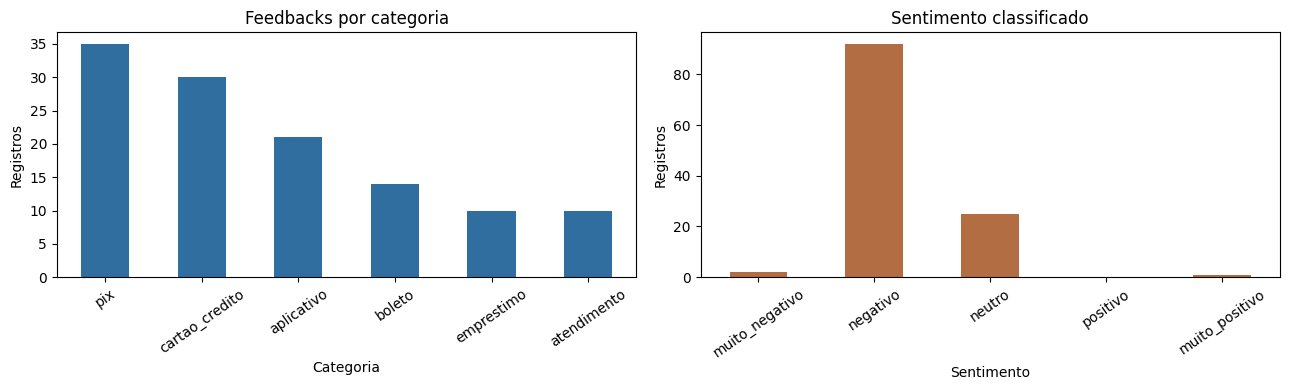

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["categoria"].value_counts().plot.bar(ax=axes[0], color="#306ea0")
axes[0].set(title="Feedbacks por categoria", xlabel="Categoria", ylabel="Registros")
ordem = ["muito_negativo", "negativo", "neutro", "positivo", "muito_positivo"]
df["sentimento"].value_counts().reindex(ordem, fill_value=0).plot.bar(ax=axes[1], color="#b26d42")
axes[1].set(title="Sentimento classificado", xlabel="Sentimento", ylabel="Registros")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=35)
fig.tight_layout()
plt.show()

## A urgência muda conforme o assunto

No gráfico, cada barra soma 100% dentro de sua categoria. Assim dá para comparar proporções sem confundir uma categoria maior com uma categoria necessariamente mais urgente.

Assuntos mais frequentes:
 assunto
pix_nao_recebido          9
pix_em_processamento      7
compra_nao_reconhecida    7
erro_ao_realizar_pix      6
compra_recusada           6
problema_login            6
erro_aplicativo           6
problema_chave_pix        5
problema_fatura           5
pix_nao_reconhecido       5


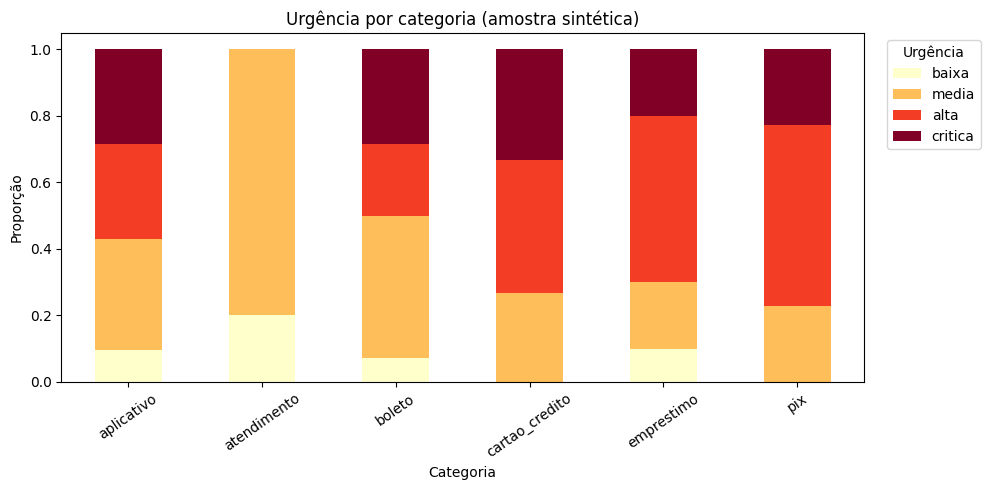

In [8]:
tabela = pd.crosstab(df["categoria"], df["urgencia"], normalize="index")
tabela = tabela.reindex(columns=["baixa", "media", "alta", "critica"], fill_value=0)
ax = tabela.plot.bar(stacked=True, figsize=(10, 5), colormap="YlOrRd")
ax.set(xlabel="Categoria", ylabel="Proporção", title="Urgência por categoria (amostra sintética)")
ax.legend(title="Urgência", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()
print("Assuntos mais frequentes:\n", df["assunto"].value_counts().head(10).to_string())

## Dois desacordos que valem a leitura

Uma taxa agregada esconde as mensagens ambíguas. A tabela mostra todos os IDs em que categoria ou assunto divergiu do rótulo de geração.

In [10]:
divergencias = avaliacao.loc[
    ~avaliacao["categoria_geracao"].eq(avaliacao["categoria"])
    | ~avaliacao["assunto_geracao"].eq(avaliacao["assunto"]),
    ["id", "feedback", "categoria_geracao", "categoria", "assunto_geracao", "assunto"],
]
display(divergencias)

,id,feedback,categoria_geracao,categoria,assunto_geracao,assunto
12,13,"Digitei o código corretamente, tenho saldo, ma...",boleto,aplicativo,erro_ao_pagar,erro_aplicativo
65,66,Tentei transferir pelo PIX três vezes e a oper...,pix,pix,erro_ao_realizar_pix,pix_em_processamento


O ID **13** não diz que o pagamento era por boleto, embora esse fosse seu rótulo de geração. No ID **66**, a transferência Pix “não conclui”, mas recebeu o assunto de processamento. O primeiro caso mostra uma limitação do próprio rótulo; o segundo sugere uma regra de classificação a revisar.

Também não avaliamos independentemente sentimento, urgência, causa ou ação sugerida. Antes de aplicar o pipeline a mensagens reais, seria necessário reunir textos anotados por pessoas, incluir casos fora da taxonomia e revisar erros por categoria.